# Difference-in-Differences: Effect of a Regional Feature Rollout on Retention
**Data: simulated** (see `src/simulate_product_data.py`). A "smart reminders" feature launched on **2025-03-03 in NA and EMEA only**; APAC and LATAM did not get it. The rollout was not randomized, and retention also improves over time product-wide, so a simple before/after comparison is biased.

The simulation plants a **true effect of +3.0 pp** on 7-day retention, so we can check whether each estimator recovers it.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)

import statsmodels.formula.api as smf
u = pd.read_parquet("../data/simulated/users_clean.parquet")
u["week"] = ((u["signup_ts"] - pd.Timestamp("2025-01-06")).dt.days // 7).astype(int)
u["treated"] = u["region"].isin(["NA", "EMEA"]).astype(int)
u["post"] = (u["signup_ts"] >= pd.Timestamp("2025-03-03")).astype(int)
u["y"] = u["retained_d7"].astype(int) * 100           # percentage points
LAUNCH_WEEK = 8
print(u.shape); u.groupby(["treated", "post"])["y"].mean().unstack().round(2)

(40000, 12)


post,0,1
treated,,
0,18.51,19.98
1,21.94,27.01


## 1. Visual check: weekly D7 retention by group

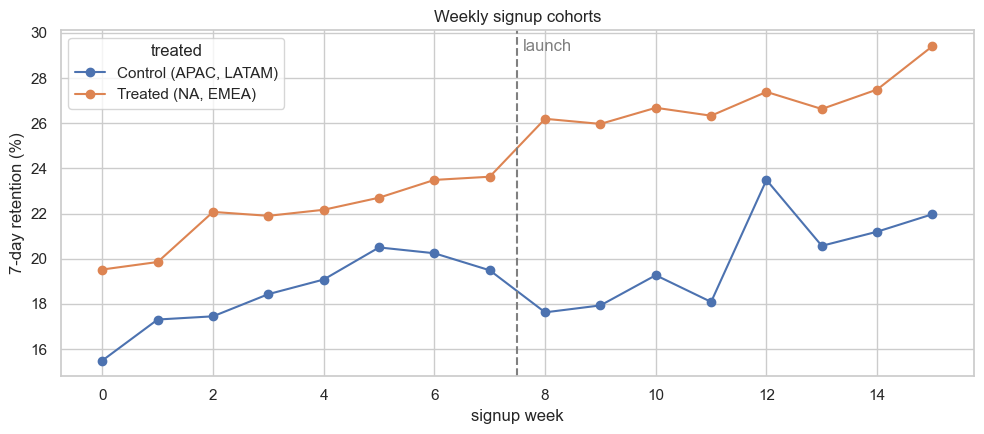

In [2]:
wk = u.groupby(["week", "treated"])["y"].mean().unstack()
ax = wk.rename(columns={0: "Control (APAC, LATAM)", 1: "Treated (NA, EMEA)"}).plot(figsize=(10, 4.5), marker="o")
ax.axvline(LAUNCH_WEEK - 0.5, color="grey", ls="--"); ax.text(LAUNCH_WEEK - 0.4, ax.get_ylim()[1]*0.97, "launch", color="grey")
ax.set(xlabel="signup week", ylabel="7-day retention (%)", title="Weekly signup cohorts")
plt.tight_layout(); plt.savefig(FIG / "did_trends.png", dpi=130); plt.show()

## 2. Naive estimators vs. DiD

In [3]:
naive_prepost = u.query("treated==1 & post==1").y.mean() - u.query("treated==1 & post==0").y.mean()
naive_cross = u.query("treated==1 & post==1").y.mean() - u.query("treated==0 & post==1").y.mean()
did_2x2 = smf.ols("y ~ treated * post", data=u).fit(cov_type="HC1")
twfe = smf.ols("y ~ treated:post + C(region) + C(week) + C(acquisition_channel) + C(platform)", data=u).fit(cov_type="HC1")
res = pd.DataFrame({
    "estimate_pp": [naive_prepost, naive_cross, did_2x2.params["treated:post"], twfe.params["treated:post"]],
    "ci_low": [np.nan, np.nan, *[m.conf_int().loc["treated:post", 0] for m in (did_2x2, twfe)]],
    "ci_high": [np.nan, np.nan, *[m.conf_int().loc["treated:post", 1] for m in (did_2x2, twfe)]],
}, index=["Naive before/after (treated only)", "Naive treated vs control (post only)",
          "DiD 2×2", "DiD two-way FE + controls"])
res["true_effect_pp"] = 3.0
res.round(2)

,estimate_pp,ci_low,ci_high,true_effect_pp
Naive before/after (treated only),5.08,NaN,NaN,3.0
Naive treated vs control (post only),7.03,NaN,NaN,3.0
DiD 2×2,3.60,1.93,5.27,3.0
DiD two-way FE + controls,3.58,1.91,5.25,3.0


The naive before/after estimate absorbs the product-wide upward trend, and the naive cross-sectional comparison absorbs the fact that NA/EMEA always had higher retention. Both overstate the effect. DiD nets out both and lands close to the planted +3 pp.

## 3. Parallel-trends check: event study

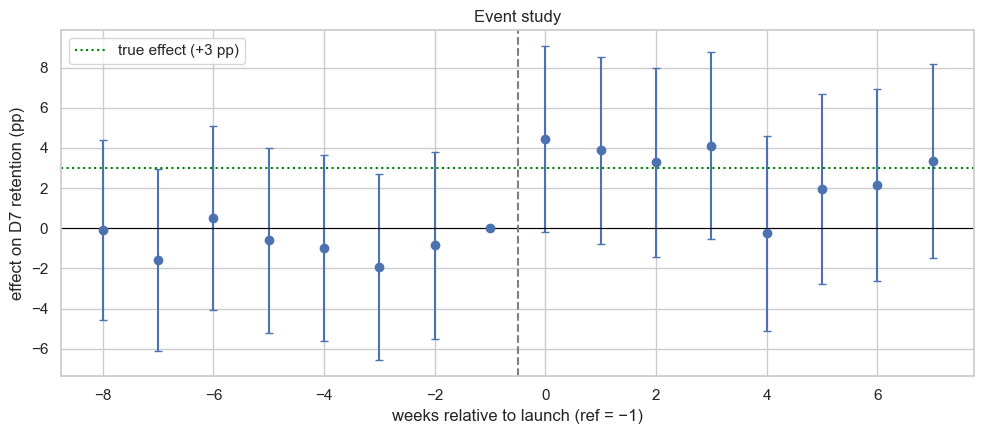

Joint test that all pre-launch coefficients are 0: F=0.25, p=0.974


In [4]:
u["rel_week"] = u["week"] - LAUNCH_WEEK
for k in sorted(u["rel_week"].unique()):
    if k != -1:
        u[f"ev_{k}".replace("-", "m")] = ((u["rel_week"] == k) & (u["treated"] == 1)).astype(int)
ev_cols = [c for c in u.columns if c.startswith("ev_")]
es = smf.ols("y ~ " + " + ".join(ev_cols) + " + C(region) + C(week)", data=u).fit(cov_type="HC1")
coef = pd.DataFrame({"k": [int(c[3:].replace("m", "-")) for c in ev_cols],
                     "b": es.params[ev_cols].values, "se": es.bse[ev_cols].values}).sort_values("k")
coef = pd.concat([coef, pd.DataFrame({"k": [-1], "b": [0.0], "se": [0.0]})]).sort_values("k")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(coef.k, coef.b, yerr=1.96 * coef.se, fmt="o", capsize=3)
ax.axhline(0, color="black", lw=0.8); ax.axvline(-0.5, color="grey", ls="--"); ax.axhline(3, color="green", ls=":", label="true effect (+3 pp)")
ax.set(xlabel="weeks relative to launch (ref = −1)", ylabel="effect on D7 retention (pp)", title="Event study"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "did_event_study.png", dpi=130); plt.show()
pre = [c for c in ev_cols if c.startswith("ev_m")]
ftest = es.f_test(" = 0, ".join(pre) + " = 0")
print(f"Joint test that all pre-launch coefficients are 0: F={float(ftest.fvalue):.2f}, p={float(ftest.pvalue):.3f}")

## 4. Robustness: placebo launch date

In [5]:
pre_df = u[u.post == 0].copy()
pre_df["fake_post"] = (pre_df["week"] >= 4).astype(int)
placebo = smf.ols("y ~ treated:fake_post + C(region) + C(week)", data=pre_df).fit(cov_type="HC1")
print(f"Placebo effect (fake launch at week 4, pre-period only): {placebo.params['treated:fake_post']:.2f} pp, p={placebo.pvalues['treated:fake_post']:.3f}")

Placebo effect (fake launch at week 4, pre-period only): -0.50 pp, p=0.669


## 5. Conclusion
- The DiD with region and week fixed effects estimates the feature's effect close to the planted **+3 pp**, with a 95% CI that covers the true value.
- Pre-launch event-study coefficients are jointly indistinguishable from zero, and a placebo launch date shows no effect. Both support the parallel-trends assumption.
- Naive comparisons would have overstated the effect by including the product-wide trend or baseline regional differences.

*Real-world caveats:* with only 2 treated and 2 control regions, cluster-robust inference at the region level is unreliable. In practice you would use more units (e.g. markets or cities), wild-cluster bootstrap, or synthetic control.